# 04 – Phân loại khả năng khách hàng mua lại

Dự đoán `target_repeat_90d` tại cutoff 01/09/2011: đơn mua mới trong cửa sổ [cutoff, cutoff + 90 ngày).

- Chỉ lấy dòng giao dịch quan sát trước cutoff làm feature; quốc gia lấy từ `country_original` trong lịch sử.
- Dòng tiếp nối của hóa đơn cũ sau cutoff không tính là đơn mua mới.
- Chạy lại pipeline từ nguồn gốc và kiểm tra độ phủ thời gian; không dùng Parquet cũ.
- Chia train/test trước khi fit; chọn ngưỡng trên validation thuộc train, không dùng test để chọn ngưỡng.
- Split ngẫu nhiên theo khách hàng cùng cutoff: chưa phải đánh giá tổng quát hóa theo thời gian.


## 0. Chuẩn bị tập dữ liệu mô hình hóa

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "classification_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy mở notebook trong repository ecommerce-behavior-analysis.")
sys.path.insert(0, str(ROOT))
from src.classification_features import run_feature_engineering

CUTOFF_DATE = "2011-09-01"
PROCESSED = ROOT / "data/processed"
MODEL_PATH = PROCESSED / "customer_modeling_dataset.parquet"
# Tạo lại cả bảng giao dịch và bảng mô hình hóa để tránh cache cũ.
df_model = run_feature_engineering(
    raw_dir=ROOT / "data/raw", processed_dir=PROCESSED,
    reports_dir=ROOT / "reports", cutoff_date=CUTOFF_DATE,
)


1. Đang đọc dữ liệu gốc...
Nguồn: online_retail_II.csv | 1,067,371 dòng
2. Đang làm sạch dữ liệu & tạo Cleaning Log...
3. Đang tích hợp nguồn dữ liệu phụ (Merge)...
[Merge 1 - Country Metadata] Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 99.71%
  -> Các giá trị chưa khớp (2,273 dòng): ['Channel Islands', 'Unspecified', 'West Indies', 'European Community']
[Merge 2 - Season Calendar]  Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 100.00%
4. Hoàn tất! Đã lưu 794,437 dòng vào 'c:\Code\KHDL\Project 2\data\processed\retail_processed.parquet' và cập nhật 'c:\Code\KHDL\Project 2\reports/cleaning_log.csv'.
Cutoff: 2011-09-01 | Horizon: 90 ngày | Nguồn quan sát đến: 2011-12-09 12:50:00
Khách hàng: 5,225 | Tỷ lệ mua lại: 42.79%


## 1. Nạp dữ liệu và chia train/test

In [2]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from src.pipeline import build_sklearn_preprocessor
from src.classification_features import FEATURE_WHITELIST

print(f"Tổng số khách hàng huấn luyện/kiểm thử: {len(df_model):,}")
print("Phân phối biến mục tiêu (target_repeat_90d):")
print(df_model["target_repeat_90d"].value_counts(normalize=True).round(4))

feature_cols = (
    FEATURE_WHITELIST["log_num_cols"]
    + FEATURE_WHITELIST["linear_num_cols"]
    + FEATURE_WHITELIST["cat_cols"]
)
X = df_model[feature_cols].copy()
y = df_model["target_repeat_90d"].values

# Chia tập dữ liệu trước khi fit bất kỳ bộ biến đổi nào (chống rò rỉ dữ liệu)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu")

Tổng số khách hàng huấn luyện/kiểm thử: 5,225
Phân phối biến mục tiêu (target_repeat_90d):
target_repeat_90d
0    0.5721
1    0.4279
Name: proportion, dtype: float64
Train: 4,180 mẫu | Test: 1,045 mẫu


## 2. So sánh mô hình bằng Stratified 5-fold CV (chỉ trên tập train)

In [3]:
models = {
    "Dummy Baseline (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "k-NN (k=15, Distance)": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200, max_depth=5, learning_rate=0.05, random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
}

cv_results = []
for name, clf in models.items():
    prep = build_sklearn_preprocessor(
        log_num_cols=FEATURE_WHITELIST["log_num_cols"],
        linear_num_cols=FEATURE_WHITELIST["linear_num_cols"],
        cat_cols=FEATURE_WHITELIST["cat_cols"],
    )
    pipe = Pipeline([("prep", prep), ("clf", clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "ROC-AUC (CV)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "PR-AUC (CV)": f"{scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}",
        "F1-Score (CV)": f"{scores['test_f1'].mean():.4f}",
        "Precision (CV)": f"{scores['test_precision'].mean():.4f}",
        "Recall (CV)": f"{scores['test_recall'].mean():.4f}",
        "_roc_mean": scores["test_roc_auc"].mean(),
    })

results_df = pd.DataFrame(cv_results).sort_values("_roc_mean", ascending=False).drop(columns=["_roc_mean"])
display(results_df)

,Model,ROC-AUC (CV),PR-AUC (CV),F1-Score (CV),Precision (CV),Recall (CV)
4,Random Forest (Balanced),0.8014 ± 0.0102,0.7697 ± 0.0202,0.6869,0.6850,0.6892
1,Logistic Regression (Balanced),0.7985 ± 0.0116,0.7615 ± 0.0205,0.6915,0.6686,0.7160
5,HistGradientBoosting,0.7981 ± 0.0121,0.7619 ± 0.0226,0.6624,0.7145,0.6177
2,"k-NN (k=15, Distance)",0.7704 ± 0.0091,0.7263 ± 0.0145,0.6508,0.6817,0.6227
3,Gaussian Naive Bayes,0.6858 ± 0.0634,0.5708 ± 0.0614,0.6006,0.4305,0.9927
0,Dummy Baseline (Most Frequent),0.5000 ± 0.0000,0.4280 ± 0.0005,0.0000,0.0000,0.0000


## 3. Đánh giá HistGradientBoosting và chọn ngưỡng F1 trên validation

HistGradientBoosting là ứng viên định trước; bảng CV ở trên chỉ để so sánh. Chưa khẳng định đây là mô hình tốt nhất.


In [4]:
# Tách một phần nhỏ từ X_train làm validation để chọn ngưỡng tối ưu F1 mà không chạm vào X_test
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

best_prep = build_sklearn_preprocessor(
    log_num_cols=FEATURE_WHITELIST["log_num_cols"],
    linear_num_cols=FEATURE_WHITELIST["linear_num_cols"],
    cat_cols=FEATURE_WHITELIST["cat_cols"],
)
best_pipe = Pipeline([
    ("prep", best_prep),
    ("clf", HistGradientBoostingClassifier(max_iter=200, max_depth=5, learning_rate=0.05, random_state=42)),
])
best_pipe.fit(X_tr, y_tr)

val_probs = best_pipe.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)
optimal_threshold = float(thresholds[best_idx])
print(f"Ngưỡng xác suất tối ưu F1 trên tập Validation: {optimal_threshold:.3f} (F1_val = {f1_scores[best_idx]:.4f})")

# Huấn luyện lại trên toàn bộ X_train và đánh giá duy nhất một lần trên X_test
best_pipe.fit(X_train, y_train)
test_probs = best_pipe.predict_proba(X_test)[:, 1]
test_preds_default = (test_probs >= 0.5).astype(int)
test_preds_tuned = (test_probs >= optimal_threshold).astype(int)

print(f"\n=== KẾT QUẢ TRÊN TẬP TEST (ROC-AUC = {roc_auc_score(y_test, test_probs):.4f} | PR-AUC = {average_precision_score(y_test, test_probs):.4f}) ===")
print("\n--- Ngưỡng mặc định (0.50) ---")
print(classification_report(y_test, test_preds_default, digits=4))
print(f"--- Ngưỡng tối ưu ({optimal_threshold:.3f}) ---")
print(classification_report(y_test, test_preds_tuned, digits=4))

Ngưỡng xác suất tối ưu F1 trên tập Validation: 0.292 (F1_val = 0.6868)

=== KẾT QUẢ TRÊN TẬP TEST (ROC-AUC = 0.7814 | PR-AUC = 0.7410) ===

--- Ngưỡng mặc định (0.50) ---
              precision    recall  f1-score   support

           0     0.7378    0.8094    0.7719       598
           1     0.7069    0.6152    0.6579       447

    accuracy                         0.7263      1045
   macro avg     0.7224    0.7123    0.7149      1045
weighted avg     0.7246    0.7263    0.7232      1045

--- Ngưỡng tối ưu (0.292) ---
              precision    recall  f1-score   support

           0     0.8024    0.5702    0.6667       598
           1     0.5855    0.8121    0.6804       447

    accuracy                         0.6737      1045
   macro avg     0.6939    0.6912    0.6735      1045
weighted avg     0.7096    0.6737    0.6725      1045



## 4. Trực quan hóa: ROC, Precision-Recall, Confusion Matrix

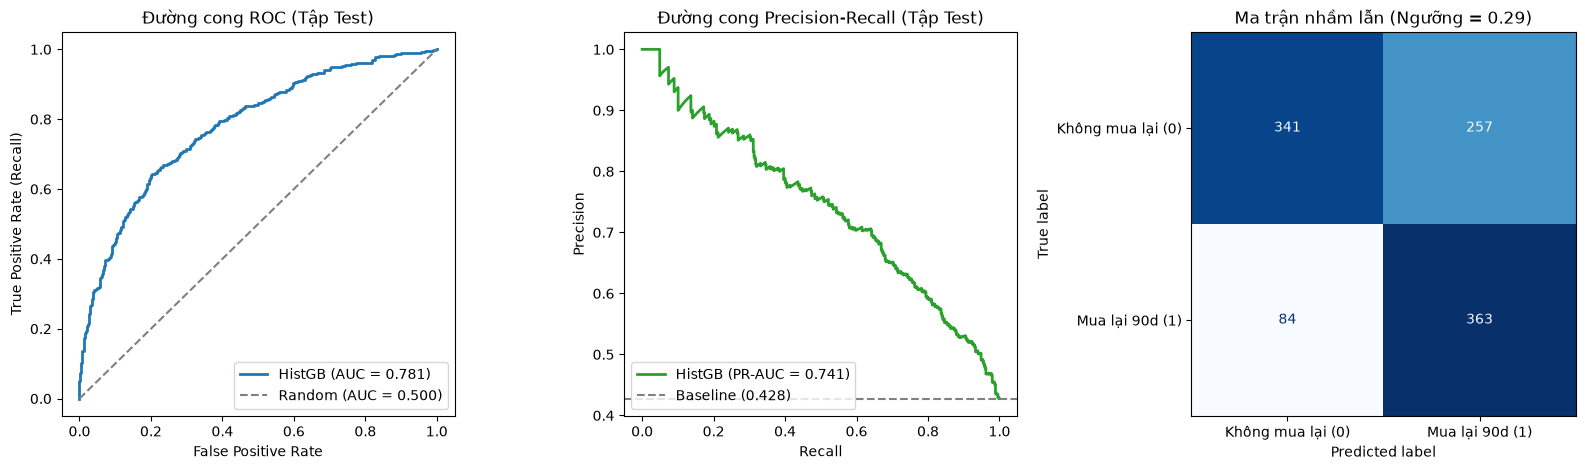

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
axes[0].plot(fpr, tpr, color="#1f77b4", lw=2, label=f"HistGB (AUC = {roc_auc_score(y_test, test_probs):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random (AUC = 0.500)")
axes[0].set_title("Đường cong ROC (Tập Test)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# 2. Precision-Recall Curve
prec_t, rec_t, _ = precision_recall_curve(y_test, test_probs)
axes[1].plot(rec_t, prec_t, color="#2ca02c", lw=2, label=f"HistGB (PR-AUC = {average_precision_score(y_test, test_probs):.3f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_title("Đường cong Precision-Recall (Tập Test)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

# 3. Confusion Matrix tại ngưỡng tối ưu
cm = confusion_matrix(y_test, test_preds_tuned)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Không mua lại (0)", "Mua lại 90d (1)"])
disp.plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title(f"Ma trận nhầm lẫn (Ngưỡng = {optimal_threshold:.2f})")

plt.tight_layout()
(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports/figures/05_classification_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()